# Customer Churn Prediction: Artificial Neural Network + K-Means Segmentation

**Executable Google Colab research notebook** · Actual customer CSV files included · Validated end-to-end training, independent evaluation, charts, saved `.keras` model and new-customer prediction.

**Based on:** [aadeshgoreja/Stage_2_Deliverables](https://github.com/aadeshgoreja/Stage_2_Deliverables) (`Clustering_Analysis`/`Data_Preparation`). Data provided separately by the user and bundled in the ZIP. Original clustering is retained **for descriptive comparison**, while a new K-Means fit is performed *only on training data* to avoid feeding original all-row clusters into the ANN.

> **Quick start:** Upload `Customer_Churn_ANN_Project.zip` to Colab's file panel (path `/content/Customer_Churn_ANN_Project.zip`) and choose **Runtime → Run all**. When only this notebook was uploaded, the first cell prompts for the ZIP. No `git clone` or independent CSV downloads needed.

**Dataset:** 6,741 customers, 12 original predictors, binary `Churn`, 4 published clusters for reference. `tenure` and `MonthlyCharges` were already scaled upstream in GitHub. Their original scaling recipe is not available and upstream leakage cannot be independently ruled out.

## 1. Locate and extract the project under `/content/`

In [1]:
from pathlib import Path
import sys, zipfile

archive = Path('/content/Customer_Churn_ANN_Project.zip')
candidates = [Path('/content/Customer_Churn_ANN_Project'), Path.cwd(), Path.cwd() / 'Customer_Churn_ANN_Project']
PROJECT_ROOT = next((p for p in candidates if (p/'data/cleaned_full_dataset.csv').is_file() and (p/'src/churn_pipeline.py').is_file()), None)
if PROJECT_ROOT is None:
    if not archive.is_file():
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError('Extract Customer_Churn_ANN_Project.zip beside this notebook first.') from exc
        print('Choose Customer_Churn_ANN_Project.zip in the file upload dialog.')
        uploaded = files.upload()
        if archive.name not in uploaded:
            raise FileNotFoundError('The expected ZIP was not uploaded: ' + archive.name)
    with zipfile.ZipFile(archive) as z:
        # The distributed ZIP contains a single Customer_Churn_ANN_Project/ directory.
        for item in z.namelist():
            if item.startswith('/') or '..' in Path(item).parts:
                raise RuntimeError(f'Unsafe archive entry: {item}')
        z.extractall('/content')
    PROJECT_ROOT = Path('/content/Customer_Churn_ANN_Project')
PROJECT_ROOT = PROJECT_ROOT.resolve()
DATA = PROJECT_ROOT / 'data'
RESULTS = PROJECT_ROOT / 'results'
assert (DATA/'cleaned_full_dataset.csv').is_file()
assert (DATA/'clustered_customer_data.csv').is_file()
sys.path.insert(0, str(PROJECT_ROOT/'src'))
print('Project:', PROJECT_ROOT)
print('Clean CSV:', DATA/'cleaned_full_dataset.csv')
print('Clustered CSV:', DATA/'clustered_customer_data.csv')
print('Results:', RESULTS)

Project: /mnt/data/Customer_Churn_ANN_Project
Clean CSV: /mnt/data/Customer_Churn_ANN_Project/data/cleaned_full_dataset.csv
Clustered CSV: /mnt/data/Customer_Churn_ANN_Project/data/clustered_customer_data.csv
Results: /mnt/data/Customer_Churn_ANN_Project/results


## 2. Check dependencies and environment

Colab normally includes TensorFlow, which Keras uses automatically. If TensorFlow is unavailable locally but PyTorch is installed, the same Keras 3 source uses Torch instead. Missing Python packages can be installed from within this cell.

In [2]:
import importlib.util, subprocess
required = {'numpy':'numpy', 'pandas':'pandas', 'sklearn':'scikit-learn', 'matplotlib':'matplotlib', 'joblib':'joblib', 'keras':'keras'}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
if importlib.util.find_spec('tensorflow') is None and importlib.util.find_spec('torch') is None:
    print('No Keras backend found; installing TensorFlow (Colab runtime).')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow>=2.16'])
import pandas as pd, numpy as np
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('TensorFlow installed:', importlib.util.find_spec('tensorflow') is not None)
print('PyTorch installed:', importlib.util.find_spec('torch') is not None)

Python: 3.13.5 | pandas: 2.2.3
TensorFlow installed: False
PyTorch installed: True


## 3. Load, inspect, and verify BOTH uploaded datasets

The cleaned file is the source for supervised fitting. The clustered file adds the published `Cluster`, `PCA1`, `PCA2` for research context, and is **not used as predictors**.

In [3]:
from IPython.display import display
from churn_pipeline import read_datasets
clean, clustered, predictor_names, audit = read_datasets(DATA/'cleaned_full_dataset.csv', DATA/'clustered_customer_data.csv')
print('Clean data shape:', clean.shape)
print('Published clustered data shape:', clustered.shape)
print('Matching original columns row-for-row:', audit['same_order_and_base_values'])
print('Missing cells:', clean.isna().sum().sum())
print('Duplicated rows:', clean.duplicated().sum())
print('Churn outcomes:')
display(clean.Churn.value_counts().sort_index().rename(index={0:'Stayed',1:'Churned'}).to_frame('customers'))
print('Predictor names:', predictor_names)
display(clean.head(6))
display(clustered[['Cluster','Churn','PCA1','PCA2']].head(6))

Clean data shape: (6741, 13)
Published clustered data shape: (6741, 16)
Matching original columns row-for-row: True
Missing cells: 0
Duplicated rows: 0
Churn outcomes:


,customers
Churn,
Stayed,4950
Churned,1791


Predictor names: ['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'MonthlyCharges', 'InternetService_DSL', 'InternetService_Fiber optic', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year']


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,Churn,InternetService_DSL,InternetService_Fiber optic,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,0,0,-1.277445,0,0,-1.321350,1,1,0,1,0,0
1,1,0,0,0.351370,1,0,-1.321350,0,1,0,0,1,0
2,0,0,1,0.799294,1,0,-1.520755,0,1,0,1,0,0
3,0,0,0,-1.277445,1,0,0.373593,1,1,0,0,1,0
4,1,0,0,1.410099,1,0,-0.457261,0,0,1,1,0,0
5,0,1,0,1.450820,1,1,0.838871,1,0,1,1,0,0


,Cluster,Churn,PCA1,PCA2
0,0,1,-1.929497,0.010157
1,1,0,-0.760229,1.095113
2,1,0,-0.551081,1.680826
3,3,1,-0.709020,-1.220920
4,1,0,0.635201,1.318103
5,2,1,1.640053,0.360414


## 4. Original GitHub segmentation — descriptive verification

Published cluster names 0–3 are historical labels; they are **not** reused as model features. The later training pipeline learns its own clusters on training rows only.

In [4]:
published_summary = clustered.groupby('Cluster')['Churn'].agg(customers='size', churn_rate='mean')
display(published_summary.style.format({'churn_rate':'{:.2%}'}))
print('Original GitHub published PCA display is saved in results/figures/04_original_github_pca.png')

,customers,churn_rate
Cluster,,
0,1589,24.80%
1,1124,4.80%
2,1882,15.67%
3,2146,48.84%


Original GitHub published PCA display is saved in results/figures/04_original_github_pca.png


## 5. Modelling design (train → validate → hold-out test)

- Stratified splitting: 4,313 train / 1,079 validation / 1,349 test using seed 42.
- Imputation and scaling fitted on training rows only.
- K-Means (`k=4`) fitted on scaled training rows only; append 4 one-hot cluster indicators to 12 original features.
- Three candidates: balanced logistic regression, balanced random forest, and neural network (32/16 ReLU with dropout, sigmoid output).
- ANN training with class weights, `binary_crossentropy`, Adam, early stopping on validation PR-AUC.
- Validation F2 threshold finds more churners; model selection by validation average precision.
- **Test results never decide the winning model or prediction threshold.**

## 6. Fit the models — REAL training and actual charts

This cell **re-trains all three models** using the bundled datasets, overwrites the prior reference results with fresh results and saves all PNG graphs and models under `/content/Customer_Churn_ANN_Project/results/`. On a CPU runtime this may take several minutes.

In [5]:
from churn_pipeline import train_experiment
summary = train_experiment(
    clean_path=DATA/'cleaned_full_dataset.csv',
    clustered_path=DATA/'clustered_customer_data.csv',
    out_dir=RESULTS,
    epochs=45,      # maximum: EarlyStopping may halt earlier
    batch_size=128,
    ann=True,
)
print('Selected on validation PR-AUC:', summary['selected_model'])
print('Actual ANN epochs:',summary['epochs_run'])


DATA AUDIT 6741 rows, 12 features; base CSVs identical: True
SPLITS: {'train': 4313, 'validation': 1079, 'test': 1349} | KERAS: torch

HELD-OUT TEST SCORES (threshold tuned only on validation):
              model  threshold  accuracy  precision_churn  recall_churn  f1_churn  roc_auc  pr_auc
logistic_regression     0.2971    0.6153           0.4024        0.9274    0.5613   0.8170  0.5959
      random_forest     0.1967    0.5745           0.3747        0.9022    0.5295   0.7891  0.5420
                ann     0.2980    0.6123           0.3998        0.9190    0.5572   0.8103  0.5875

SELECTED (via validation AP): ann

              precision    recall  f1-score   support

           0     0.9449    0.5015    0.6552       991
           1     0.3998    0.9190    0.5572       358

    accuracy                         0.6123      1349
   macro avg     0.6723    0.7103    0.6062      1349
weighted avg     0.8002    0.6123    0.6292      1349

Saved results to: /mnt/data/Customer_Churn_ANN

## 7. Compare scores and thresholds

Two different decisions are shown: the standard 0.50 probability cutoff, and a validation-tuned F2 cutoff. **A low tuned cutoff increases recall, but often creates additional false alarms and lowers accuracy.**

In [6]:
import json
summary=json.loads((RESULTS/'metrics.json').read_text())
model_scores=pd.read_csv(RESULTS/'model_scores.csv')
print('TEST metrics with validation-selected threshold:')
display(model_scores.round(4))
rows=[]
for model, blocks in summary['test_metrics'].items():
    for threshold_type, scores in blocks.items():
        rows.append({'model':model,'threshold_type':threshold_type,**{k:v for k,v in scores.items() if k not in ('tn_fp_fn_tp','confusion_matrix')}})
all_scores=pd.DataFrame(rows)
print('TEST metrics at fixed 0.5 versus validation threshold:')
display(all_scores.round(4))
print('Validation-selected best model:',summary['selected_model'])

TEST metrics with validation-selected threshold:


,model,decision_threshold,threshold,accuracy,precision_churn,recall_churn,f1_churn,roc_auc,pr_auc
0,logistic_regression,0.2971,0.2971,0.6153,0.4024,0.9274,0.5613,0.8170,0.5959
1,random_forest,0.1967,0.1967,0.5745,0.3747,0.9022,0.5295,0.7891,0.5420
2,ann,0.2980,0.2980,0.6123,0.3998,0.9190,0.5572,0.8103,0.5875


TEST metrics at fixed 0.5 versus validation threshold:


,model,threshold_type,threshold,accuracy,precision_churn,recall_churn,f1_churn,roc_auc,pr_auc
0,logistic_regression,threshold_0_5,0.5000,0.7346,0.5000,0.7598,0.6031,0.8170,0.5959
1,logistic_regression,validation_threshold,0.2971,0.6153,0.4024,0.9274,0.5613,0.8170,0.5959
2,random_forest,threshold_0_5,0.5000,0.7517,0.5283,0.6006,0.5621,0.7891,0.5420
3,random_forest,validation_threshold,0.1967,0.5745,0.3747,0.9022,0.5295,0.7891,0.5420
4,ann,threshold_0_5,0.5000,0.7198,0.4822,0.7570,0.5891,0.8103,0.5875
5,ann,validation_threshold,0.2980,0.6123,0.3998,0.9190,0.5572,0.8103,0.5875


Validation-selected best model: ann


## 8. Exploratory and customer-segmentation visuals

01_churn_and_tenure.png


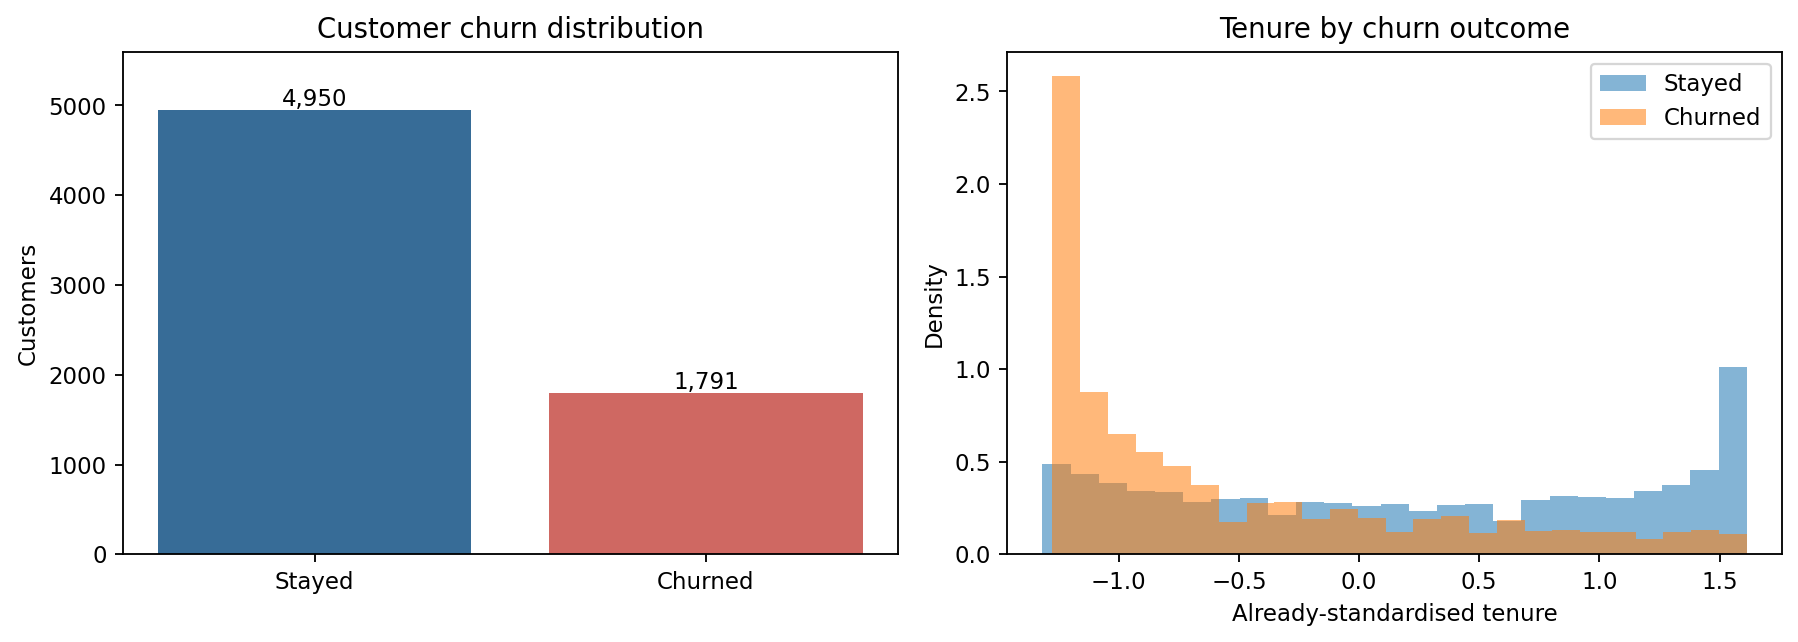

02_monthly_charges.png


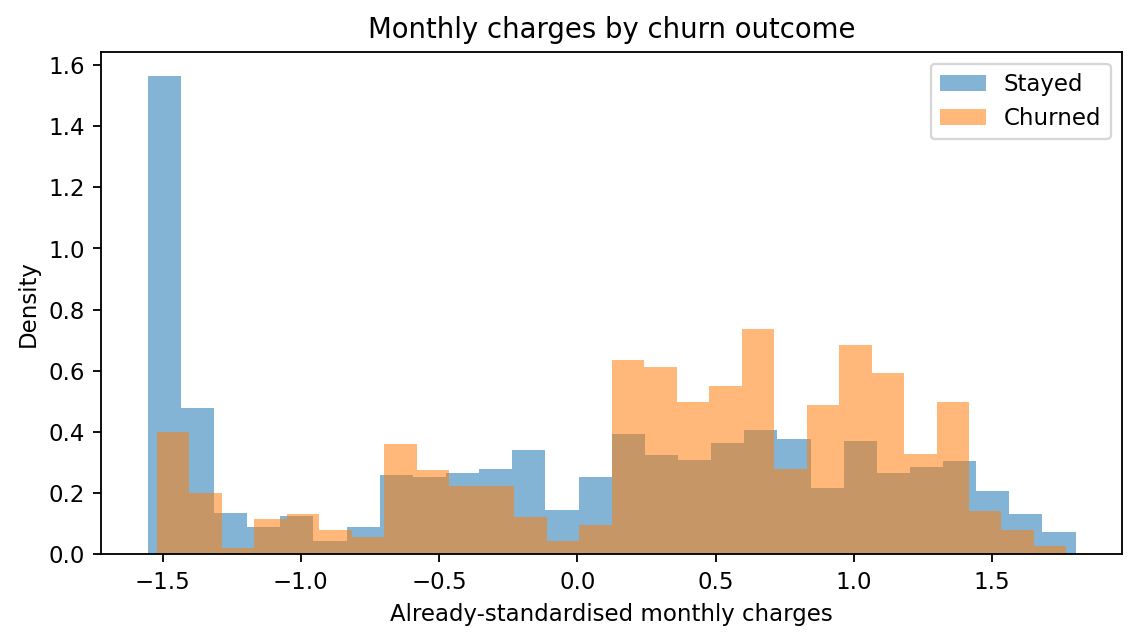

03_published_clusters.png


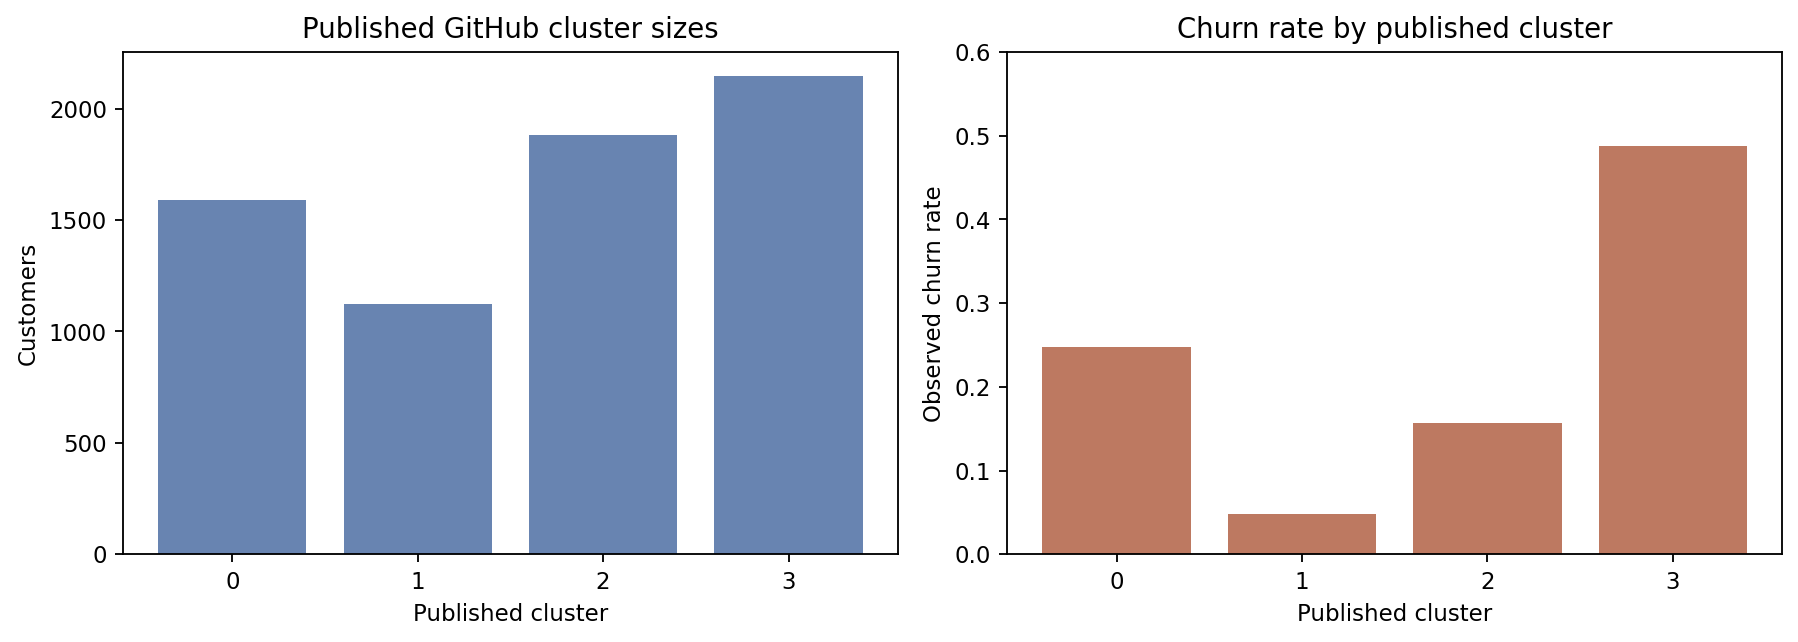

04_original_github_pca.png


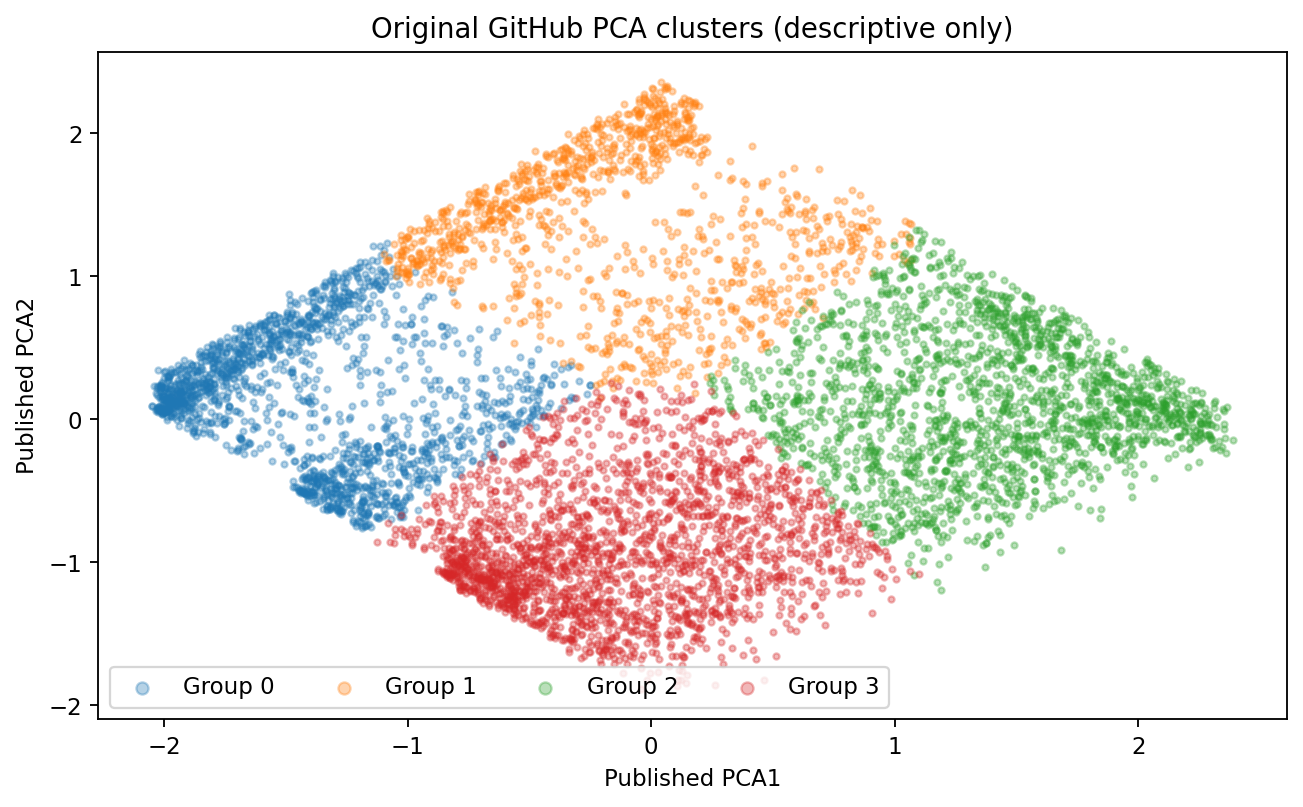

05_train_only_clusters.png


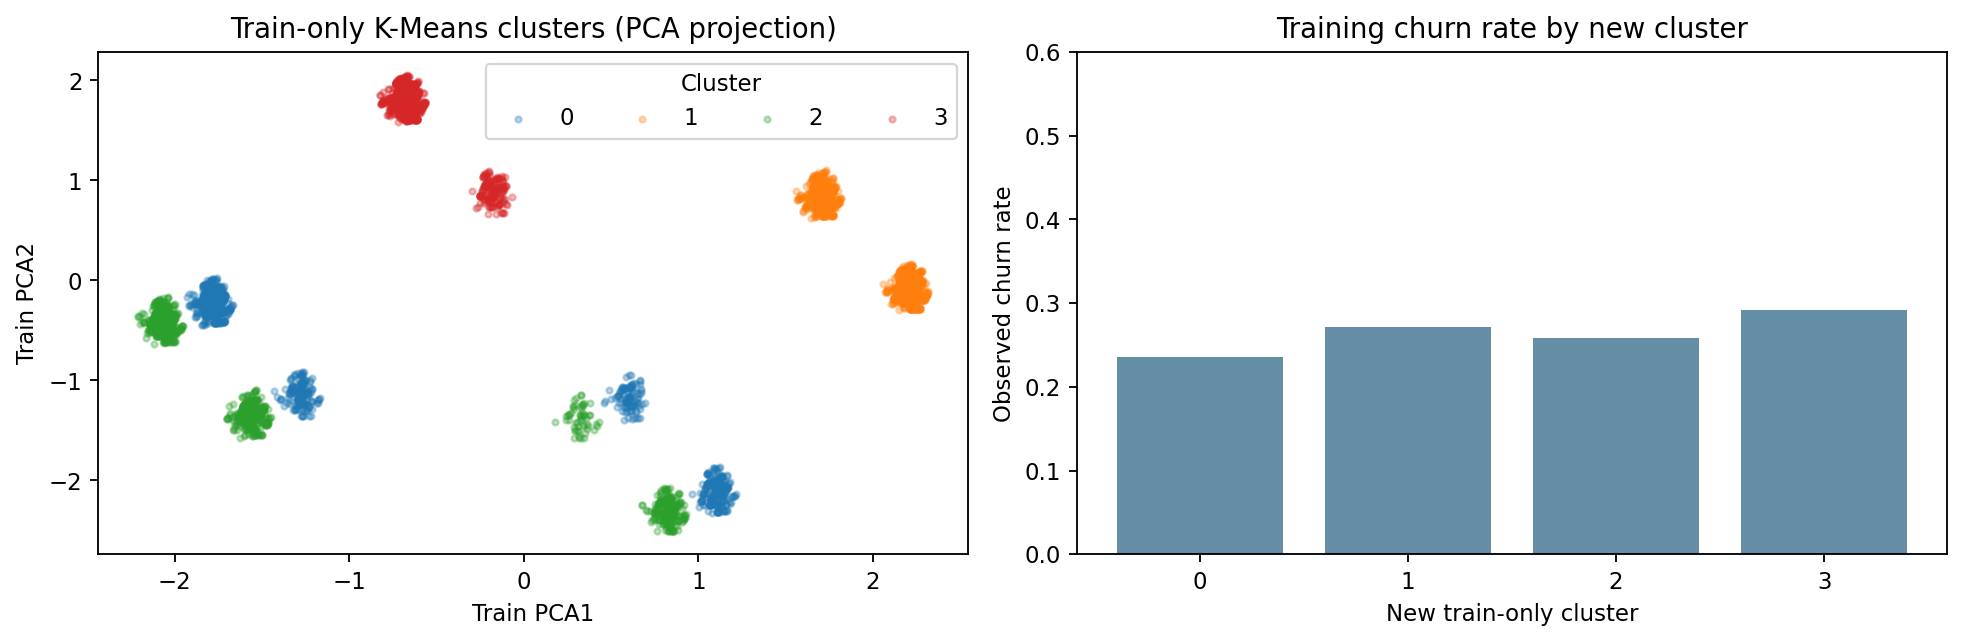

In [7]:
from IPython.display import Image

def show_png(name, width=860):
    png=RESULTS/'figures'/name
    assert png.is_file(), f'Missing graph: {png}'
    print(name)
    display(Image(filename=str(png),width=width))

for name in ['01_churn_and_tenure.png','02_monthly_charges.png',
             '03_published_clusters.png','04_original_github_pca.png','05_train_only_clusters.png']:
    show_png(name)

## 9. ANN training history — loss, accuracy, ROC-AUC and PR-AUC

ann_learning_curves.png


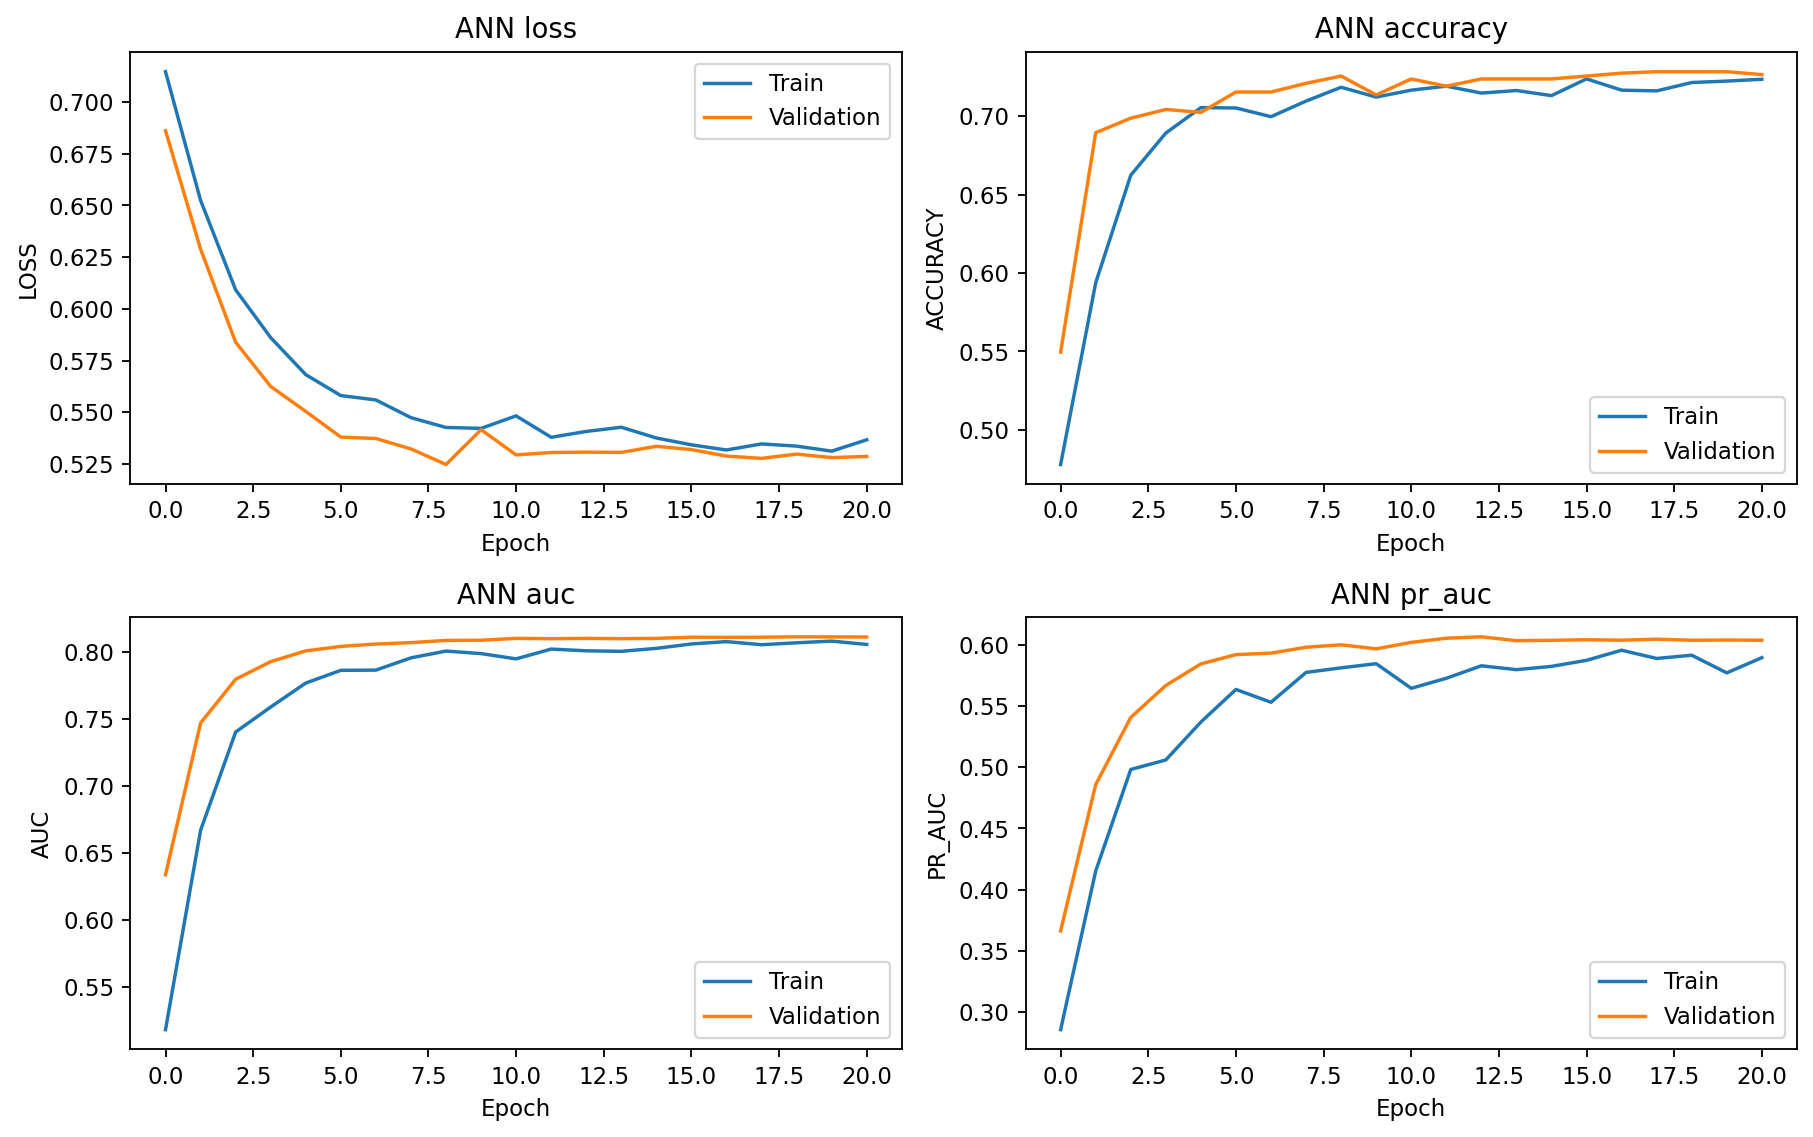

Best validation PR-AUC: 0.6065


In [8]:
show_png('ann_learning_curves.png', 990)
print('Best validation PR-AUC:',round(max(json.loads((RESULTS/'ann_training_history.json').read_text())['val_pr_auc']),4))

## 10. Model performance visuals: ROC curves, precision–recall curves and comparison

model_comparison.png


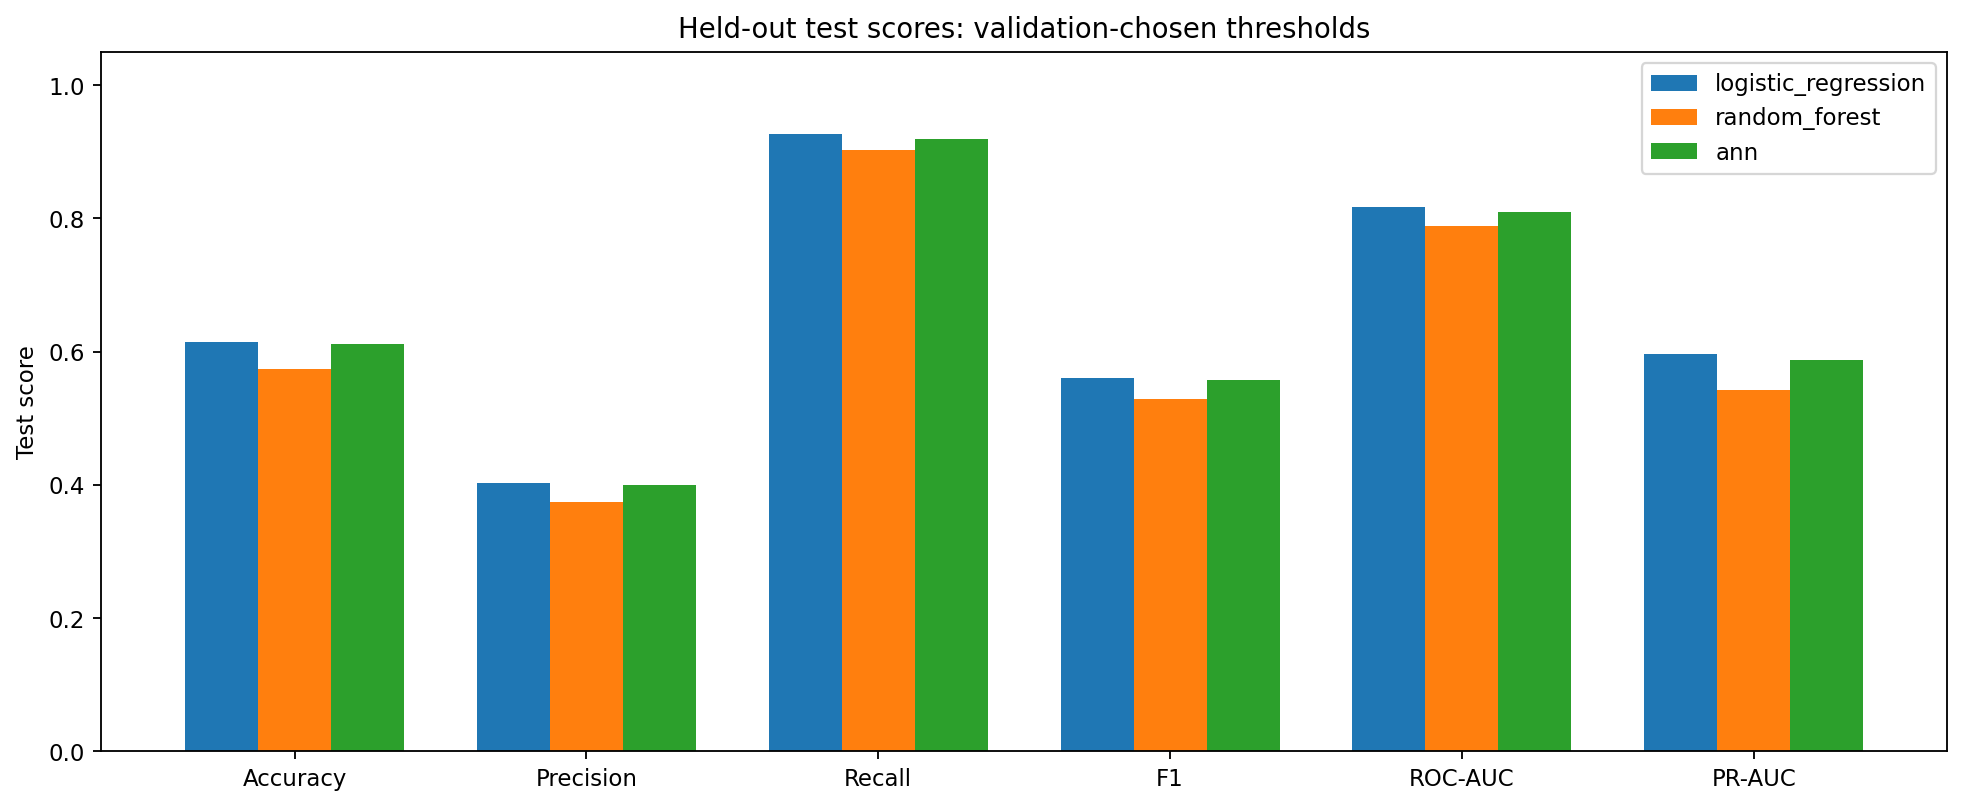

roc_test.png


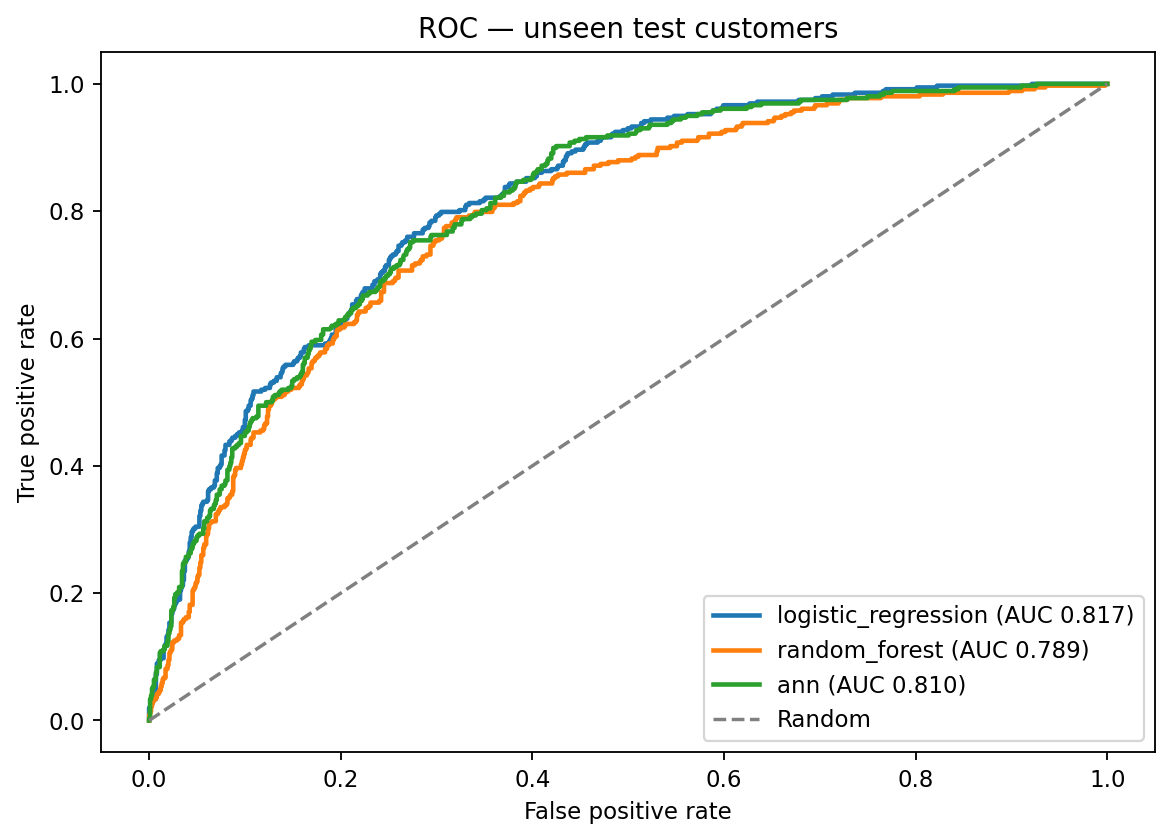

precision_recall_test.png


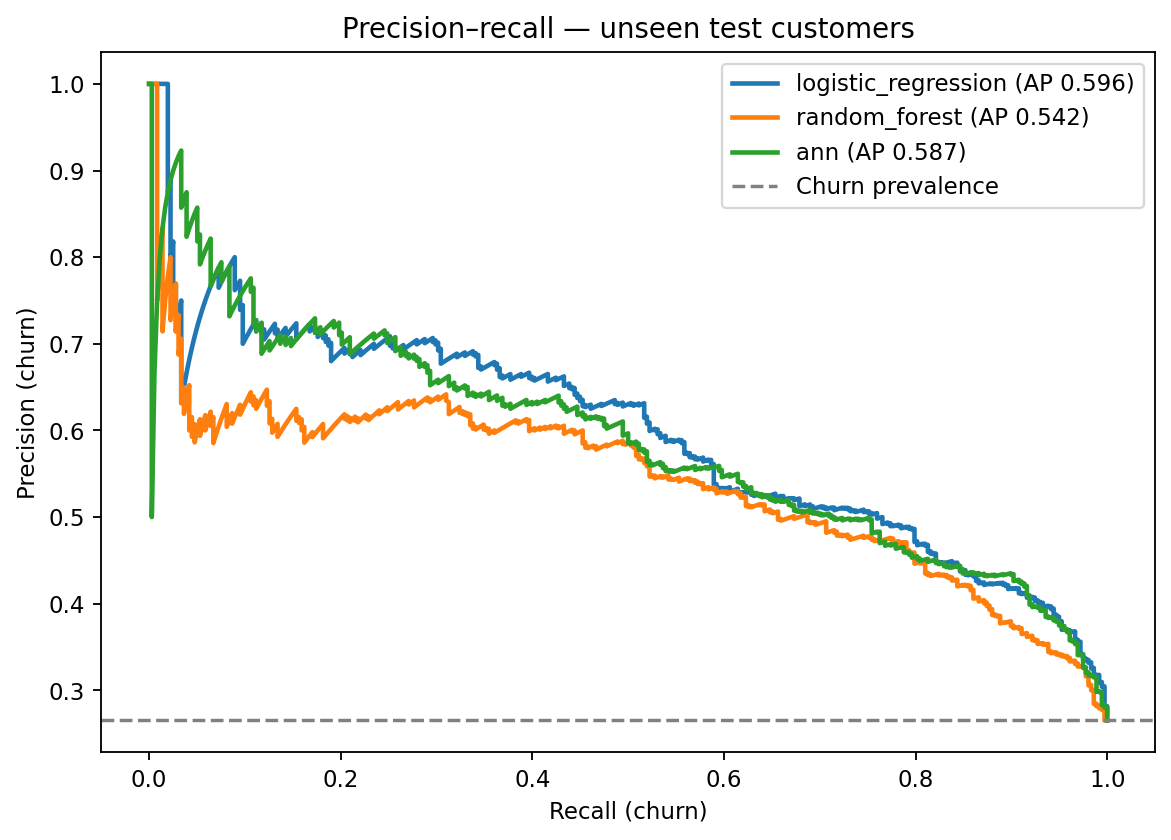

In [9]:
for name in ['model_comparison.png','roc_test.png','precision_recall_test.png']:
    show_png(name,920)

## 11. Confusion matrices for all three models

confusion_logistic_regression.png


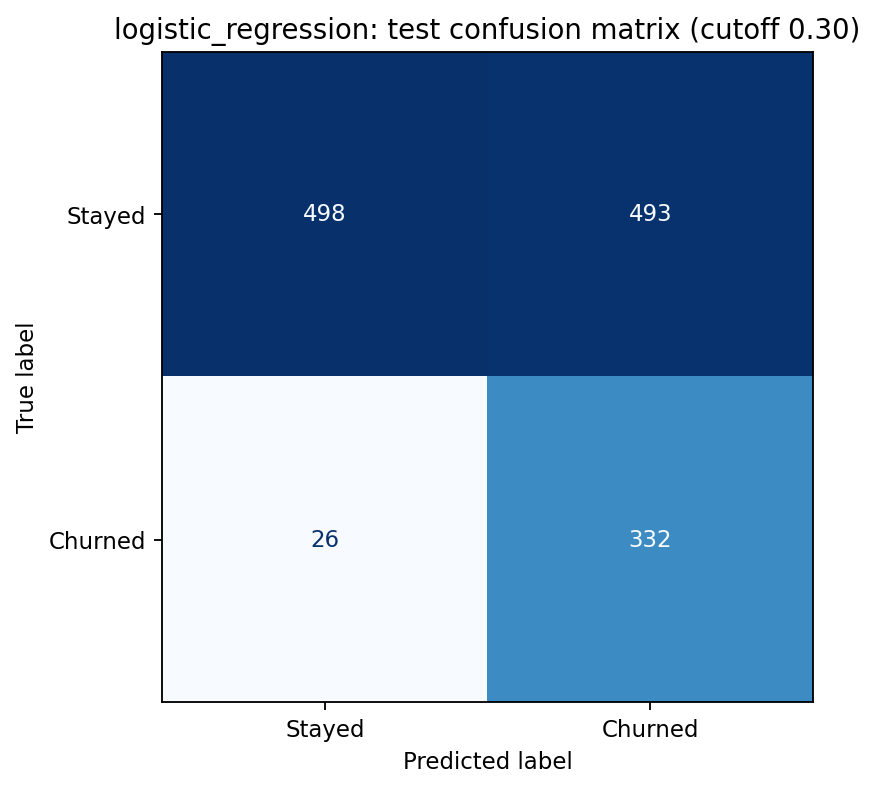

confusion_random_forest.png


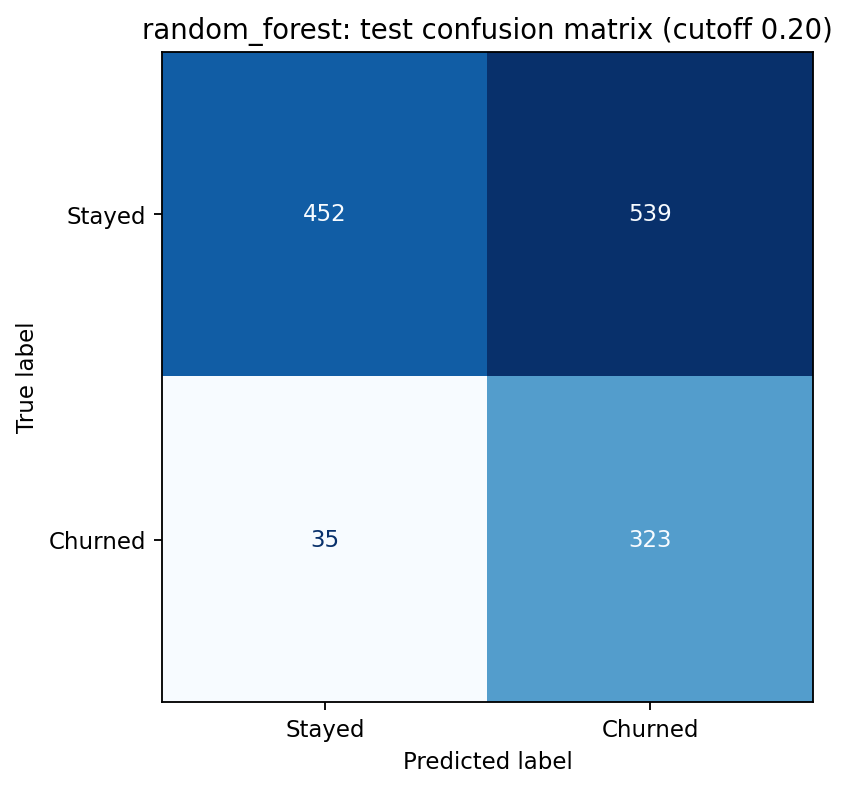

confusion_ann.png


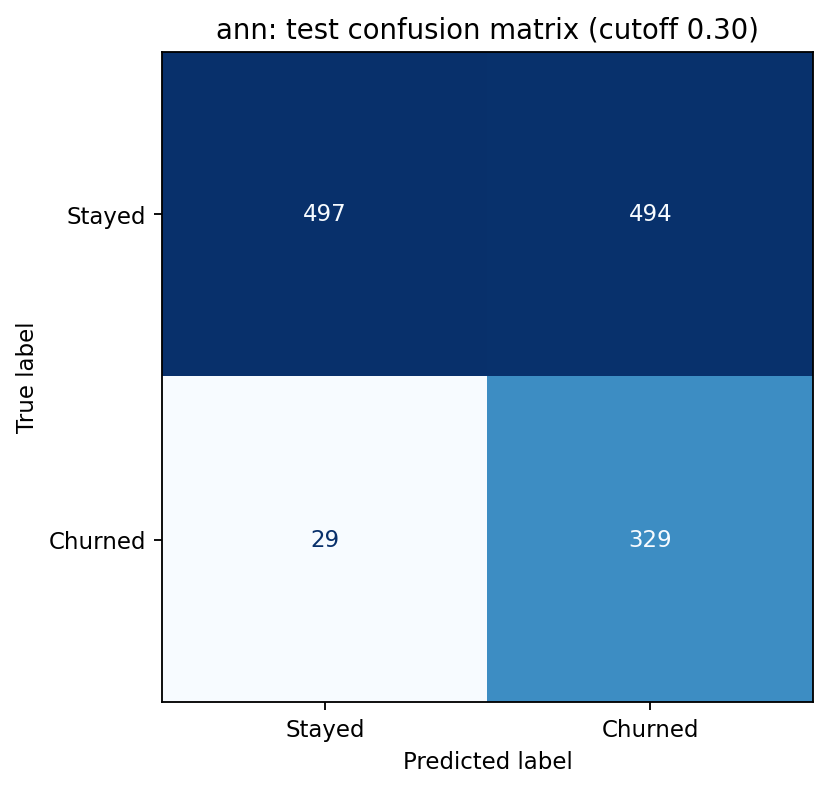

ANN retained/churn precision, recall and class support:
              precision    recall  f1-score   support

           0     0.9449    0.5015    0.6552       991
           1     0.3998    0.9190    0.5572       358

    accuracy                         0.6123      1349
   macro avg     0.6723    0.7103    0.6062      1349
weighted avg     0.8002    0.6123    0.6292      1349



In [10]:
for name in ['confusion_logistic_regression.png','confusion_random_forest.png','confusion_ann.png']:
    show_png(name,650)
print('ANN retained/churn precision, recall and class support:')
print((RESULTS/'selected_model_classification_report.txt').read_text())

## 12. Feature importance and saved model files

The forest importance is a heuristic of predictive feature use, **not a causal explanation**. New one-hot clusters are appended to the features.

random_forest_feature_importance.png


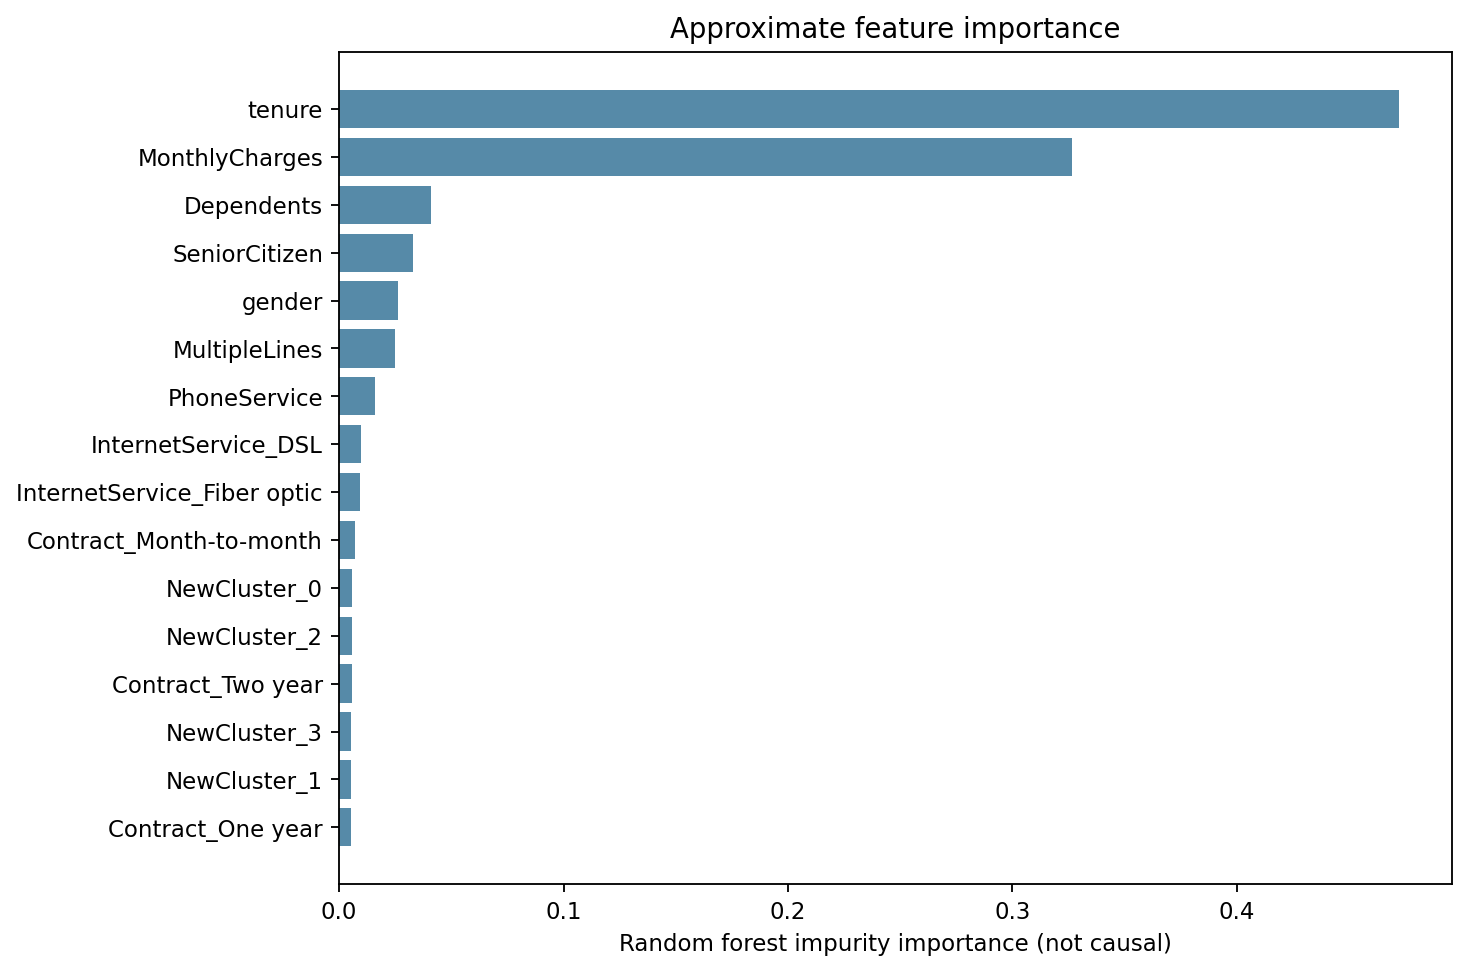

Saved models and preprocessing:
customer_churn_ann.keras 42.5 KB
logistic_regression.joblib 1.0 KB
preprocessing.joblib 19.7 KB
random_forest.joblib 17423.8 KB


In [11]:
show_png('random_forest_feature_importance.png',950)
print('Saved models and preprocessing:')
for f in sorted((RESULTS/'models').iterdir()):
    print(f.name,round(f.stat().st_size/1024,1),'KB')

## 13. Infer churn risk for example new customers

These 10 example records are rows from the **already pre-standardised source representation**. Without the upstream encoding/scaling recipe, do **not** enter raw tenure in months or raw currency charges and assume predictions will be valid.

In [12]:
from predict import predict_file
input_file=RESULTS/'example_new_customers.csv'
print('Selected-model prediction:')
selected_output=predict_file(input_file, RESULTS/'example_predictions_selected.csv',RESULTS)
display(selected_output.head(10))
print('ANN prediction (always exercise saved .keras model):')
ann_output=predict_file(input_file, RESULTS/'example_predictions_ann.csv',RESULTS, model_name='ann')
display(ann_output.head(10))

Selected-model prediction:
 churn_probability  predicted_churn risk_band
          0.485284                1    Medium
          0.266825                0       Low
          0.048491                0       Low
          0.809038                1      High
          0.122656                0       Low
          0.146333                0       Low
          0.097842                0       Low
          0.483919                1    Medium
          0.813636                1      High
          0.109725                0       Low
Saved: /mnt/data/Customer_Churn_ANN_Project/results/example_predictions_selected.csv


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,InternetService_DSL,InternetService_Fiber optic,Contract_Month-to-month,Contract_One year,Contract_Two year,churn_probability,predicted_churn,risk_band,model_used
0,1,0,0,-0.340876,1,0,-0.224622,1,0,1,0,0,0.485284,1,Medium,ann
1,0,0,0,1.491540,1,0,1.337384,1,0,1,0,0,0.266825,0,Low,ann
2,0,0,1,1.002896,1,0,-0.390793,0,1,0,0,1,0.048491,0,Low,ann
3,0,1,0,-0.218715,1,1,1.503555,1,0,0,0,1,0.809038,1,High,ann
4,1,0,0,1.369379,0,0,-1.188413,0,1,1,0,0,0.122656,0,Low,ann
5,0,0,1,1.450820,1,0,0.672701,1,0,1,0,0,0.146333,0,Low,ann
6,0,0,1,-0.137274,1,1,-1.487520,0,1,0,1,0,0.097842,0,Low,ann
7,0,0,0,1.043616,1,1,1.536789,0,1,1,0,0,0.483919,1,Medium,ann
8,0,0,0,-1.155283,1,0,0.406827,1,0,0,0,1,0.813636,1,High,ann
9,1,0,1,1.084337,1,1,0.739169,0,1,0,0,1,0.109725,0,Low,ann


ANN prediction (always exercise saved .keras model):
 churn_probability  predicted_churn risk_band
          0.485284                1    Medium
          0.266825                0       Low
          0.048491                0       Low
          0.809038                1      High
          0.122656                0       Low
          0.146333                0       Low
          0.097842                0       Low
          0.483919                1    Medium
          0.813636                1      High
          0.109725                0       Low
Saved: /mnt/data/Customer_Churn_ANN_Project/results/example_predictions_ann.csv


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,InternetService_DSL,InternetService_Fiber optic,Contract_Month-to-month,Contract_One year,Contract_Two year,churn_probability,predicted_churn,risk_band,model_used
0,1,0,0,-0.340876,1,0,-0.224622,1,0,1,0,0,0.485284,1,Medium,ann
1,0,0,0,1.491540,1,0,1.337384,1,0,1,0,0,0.266825,0,Low,ann
2,0,0,1,1.002896,1,0,-0.390793,0,1,0,0,1,0.048491,0,Low,ann
3,0,1,0,-0.218715,1,1,1.503555,1,0,0,0,1,0.809038,1,High,ann
4,1,0,0,1.369379,0,0,-1.188413,0,1,1,0,0,0.122656,0,Low,ann
5,0,0,1,1.450820,1,0,0.672701,1,0,1,0,0,0.146333,0,Low,ann
6,0,0,1,-0.137274,1,1,-1.487520,0,1,0,1,0,0.097842,0,Low,ann
7,0,0,0,1.043616,1,1,1.536789,0,1,1,0,0,0.483919,1,Medium,ann
8,0,0,0,-1.155283,1,0,0.406827,1,0,0,0,1,0.813636,1,High,ann
9,1,0,1,1.084337,1,1,0.739169,0,1,0,0,1,0.109725,0,Low,ann


## 14. Run automated validation checks

In [13]:
import subprocess
completed=subprocess.run([sys.executable,'-m','unittest','discover','-s',str(PROJECT_ROOT/'tests'),'-v'],
                         cwd=PROJECT_ROOT,capture_output=True,text=True)
print(completed.stdout)
print(completed.stderr)
assert completed.returncode==0, 'One or more validation checks failed.'
print('All automated tests passed.')

 churn_probability  predicted_churn risk_band
          0.450884                1    Medium
          0.278181                0       Low
          0.059456                0       Low
          0.854419                1      High
          0.068462                0       Low
          0.126251                0       Low
          0.084849                0       Low
          0.430469                1    Medium
          0.792969                1      High
          0.137683                0       Low
Saved: /mnt/data/Customer_Churn_ANN_Project/results/test_inference_output.csv
 churn_probability  predicted_churn risk_band
          0.485284                1    Medium
          0.266825                0       Low
          0.048491                0       Low
          0.809038                1      High
          0.122656                0       Low
          0.146333                0       Low
          0.097842                0       Low
          0.483919                1    Medium
  

## 15. Export regenerated results as a ZIP

The **full original project ZIP** already includes all source/data/reference model files. This code additionally packages the regenerated results in an easy-to-save archive. The runtime-local path in Colab is `/content/Customer_Churn_ANN_Project_Colab_Results.zip`.

In [14]:
import zipfile
export_path=Path('/content/Customer_Churn_ANN_Project_Colab_Results.zip') if Path('/content').exists() else PROJECT_ROOT.parent/'Customer_Churn_ANN_Project_Colab_Results.zip'
with zipfile.ZipFile(export_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for f in sorted(RESULTS.rglob('*')):
        if f.is_file() and '__pycache__' not in str(f):
            z.write(f,arcname=str(Path('results')/f.relative_to(RESULTS)))
print(f'Regenerated results ZIP: {export_path} ({export_path.stat().st_size/1024/1024:.1f} MB)')
try:
    from IPython.display import FileLink
    display(FileLink(str(export_path)))
except Exception:
    pass
# To download directly in Colab, uncomment these two lines:
# from google.colab import files
# files.download(str(export_path))

Regenerated results ZIP: /mnt/data/Customer_Churn_ANN_Project_Colab_Results.zip (6.1 MB)


/mnt/data/Customer_Churn_ANN_Project_Colab_Results.zip

## Final interpretation and research cautions

**What is complete:** audited CSVs, real 3-way stratified train/validation/test, new train-only clustering, trained ANN with early stopping, comparison against two classifiers, validation-only threshold selection, held-out testing, reproducible saved models, inference, full score reports and PNG visualisations.

**What cannot be proven from the source files alone:** how upstream raw numeric values were standardised, whether the original full-dataset cleaning used future test statistics, or how a new real-world customer's raw monthly charges should be converted into the required standardized units. This project therefore supports experiments on the supplied encoded records, not a ready-to-deploy subscription-retention production system.

**Original GitHub source:** https://github.com/aadeshgoreja/Stage_2_Deliverables. Read the included README and `docs/METHODOLOGY_AND_DATA_LIMITATIONS.md` for reproducibility and limitations.

## Reference-run chart preview (saved outputs from the packaged offline test)
These embedded images come from the actual completed reference training run. Running the notebook regenerates the charts in Sections 8–12 on the active Colab backend.

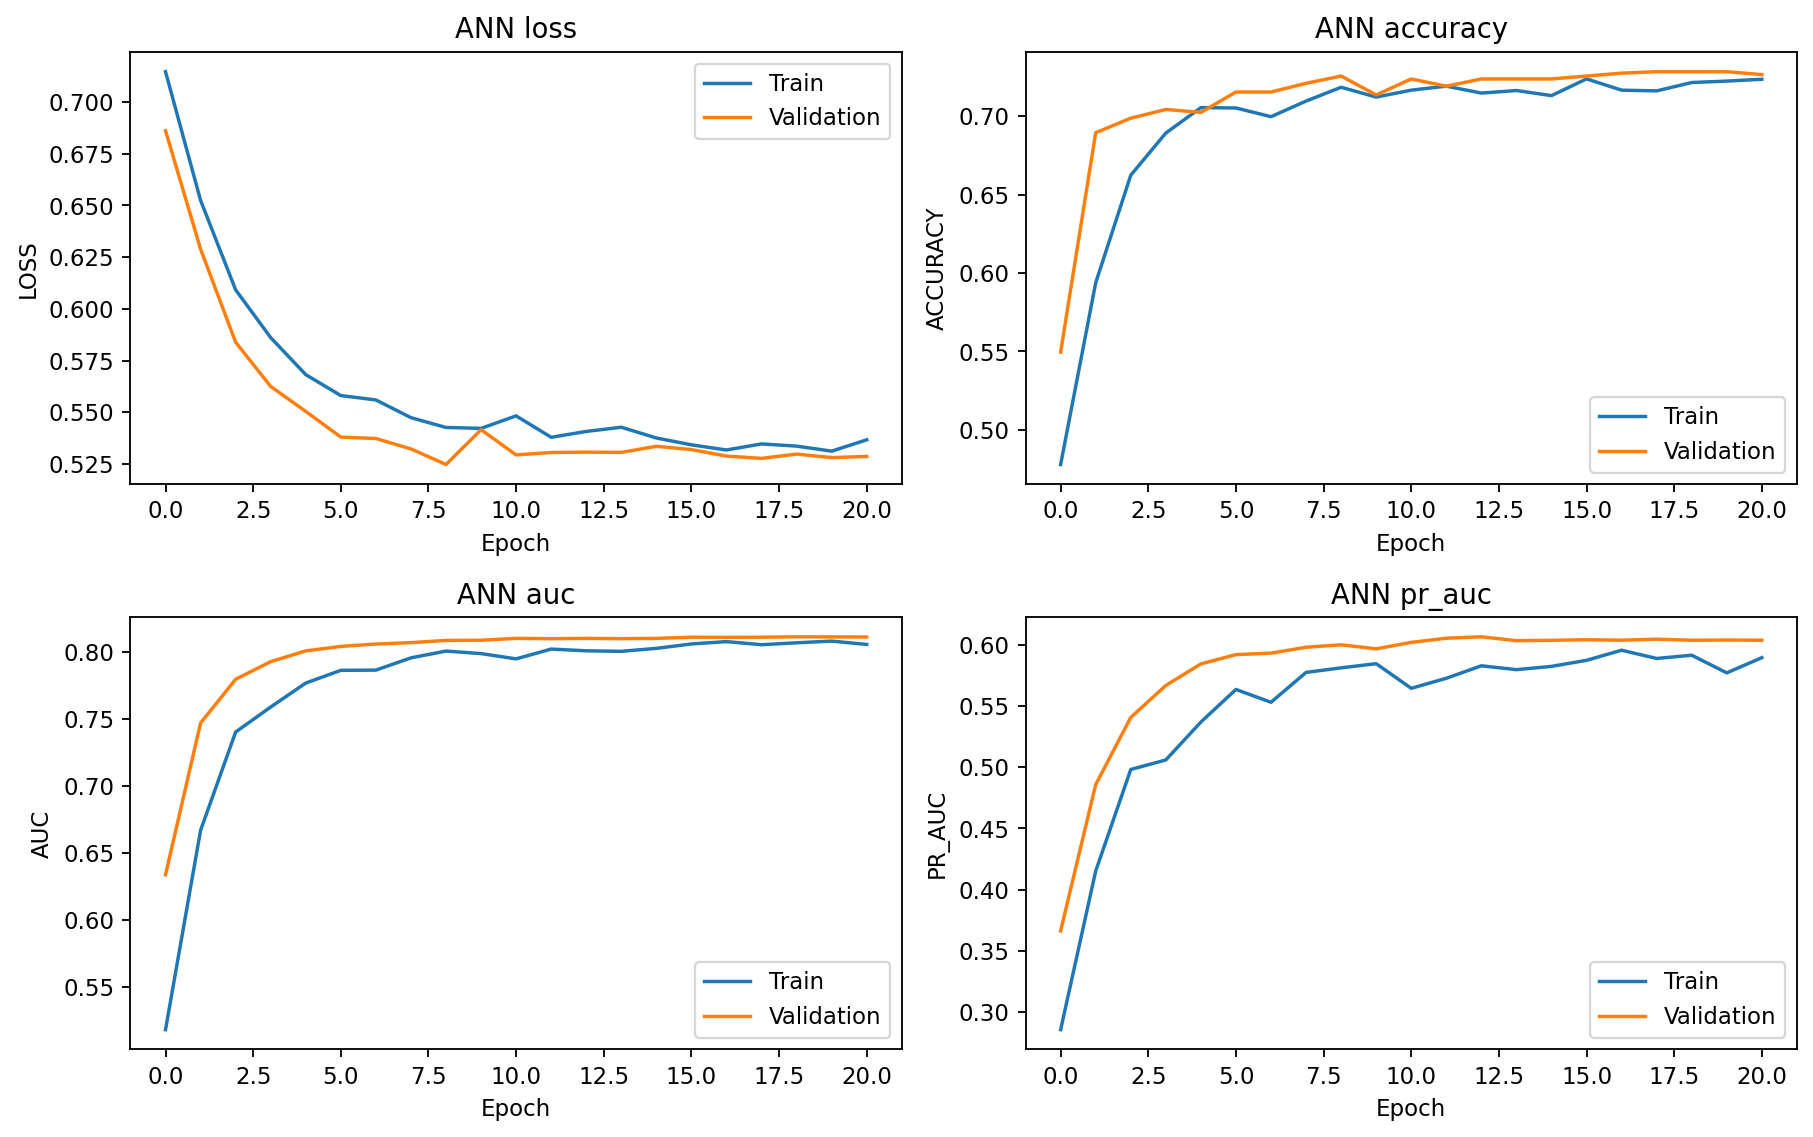

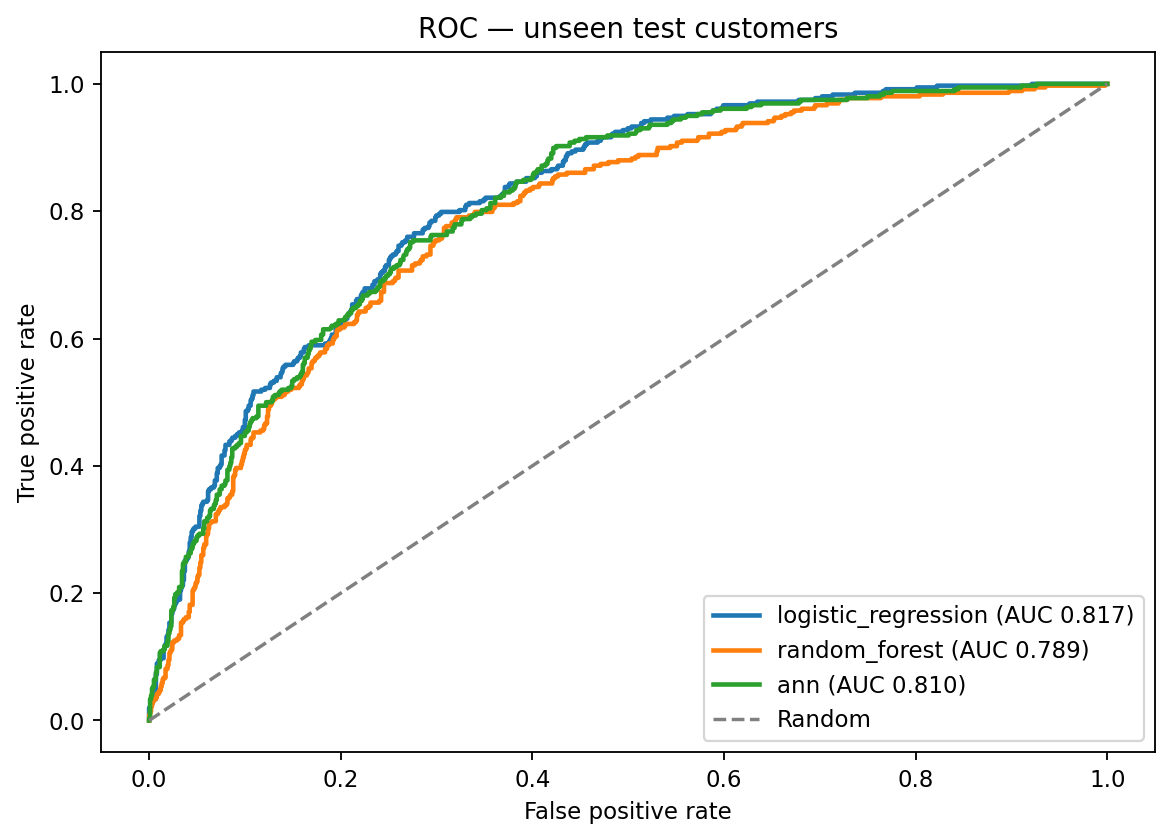

In [15]:
# Reference charts embedded in this notebook; re-created on Runtime → Run all.
from IPython.display import Image, display
for image_name in ['ann_learning_curves.png','roc_test.png']:
    display(Image(filename=str(RESULTS/'figures'/image_name),width=760))